# Model comparison

Scores every baseline and candidate model against one trusted actuals series,
using the shared metric functions in `scripts/evaluation.py`, over the test
year 2025-07-01 to 2026-06-30.

In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path("..").resolve()))
from scripts.evaluation import load_data, score

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True})

DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
REPORTS_DIR = Path("../reports")
TEST_START, TEST_END = "2025-07-01", "2026-06-30"

BASELINE = "naive_day_ahead"
GREY = "#b0b0b0"


## Actuals

In [2]:
elec = load_data(DATA_DIR)
test = elec.loc[TEST_START:TEST_END]

actual_utc = test["load_mw"].copy()
actual_utc.index = actual_utc.index.tz_convert("UTC")
print(f"{len(actual_utc):,} hourly rows, {actual_utc.index.min()} to {actual_utc.index.max()}")

8,759 hourly rows, 2025-06-30 22:00:00+00:00 to 2026-06-30 21:00:00+00:00


In [3]:
matched = pd.read_csv(REPORTS_DIR / "manager_report_20261021/diagnostics/matched_hourly.csv")
matched["delivery_time"] = pd.to_datetime(matched["delivery_time"], utc=True)
matched = matched.set_index("delivery_time").sort_index()

check = pd.concat([actual_utc, matched["actual_mw"]], axis=1, join="inner")
check.columns = ["actual_mw", "actual_mw_other"]
max_diff = (check["actual_mw"] - check["actual_mw_other"]).abs().max()
print(f"{len(check):,} rows cross-checked, max diff {max_diff:.4f} MW")

8,759 rows cross-checked, max diff 0.0000 MW


## Score each model

In [4]:
results = {}

for path in sorted(RESULTS_DIR.glob("*.json")):
    payload = json.loads(path.read_text())
    results[payload["model"]] = payload["mean_metrics"]

In [5]:
all_test = pd.read_csv(REPORTS_DIR / "forecasts/all_test.csv.gz")
all_test["delivery_time"] = pd.to_datetime(all_test["delivery_time"], utc=True)

for model_name in ["seasonal_naive", "comparable_days", "rte_proxy", "rte_bias_proxy", "rte_correction_proxy"]:
    fc = (
        all_test[all_test["model"] == model_name]
        .set_index("delivery_time")["prediction_mw"]
        .sort_index()
    )
    results[model_name] = score(actual_utc, fc)

In [6]:
for col, label in [
    ("prior_prediction_mw", "prior_candidate"),
    ("selected_prediction_mw", "best_candidate"),
]:
    results[label] = score(actual_utc, matched[col])

rte_cross_check = score(actual_utc, matched["rte_prediction_mw"])
print("rte_benchmark (own):      ", results["rte_benchmark"])
print("rte_benchmark (cross-check):", rte_cross_check)

rte_benchmark (own):       {'MAE_MW': 1439.9112570152492, 'RMSE_MW': 1778.3331807014604, 'MAPE_pct': 2.8597133349716097}
rte_benchmark (cross-check): {'MAE_MW': 1438.982075579404, 'RMSE_MW': 1782.6466724530926, 'MAPE_pct': 2.859739939725177}


## Leaderboard

Model provenance:

| model | source |
| --- | --- |
| `naive_day_ahead` | `results/naive_day_ahead.json` - lag-24h naive forecast, 4-fold walk-forward |
| `seasonal_naive_weekly` | `results/seasonal_naive_weekly.json` - lag-168h naive forecast, 4-fold walk-forward |
| `rte_benchmark` | `results/rte_benchmark.json` - RTE's published day-ahead forecast, 4-fold walk-forward |
| `seasonal_naive` | `reports/forecasts/all_test.csv.gz` - lag-168h naive forecast, continuous daily-origin replay |
| `comparable_days` | `reports/forecasts/all_test.csv.gz` - nearest historical comparable-day average |
| `rte_proxy` | `reports/forecasts/all_test.csv.gz` - RTE forecast replay under assumed availability |
| `rte_bias_proxy` | `reports/forecasts/all_test.csv.gz` - RTE forecast with rolling bias correction |
| `rte_correction_proxy` | `reports/forecasts/all_test.csv.gz` - earlier bias-correction model variant |
| `prior_candidate` | `matched_hourly.csv` (`prior_prediction_mw`) - earlier selected research-pipeline model |
| `best_candidate` | `matched_hourly.csv` (`selected_prediction_mw`) - current selected research-pipeline model |

`naive_day_ahead` is the project baseline; it is shaded grey in the charts below so every
other model's bar can be read as an improvement (or not) relative to it.

In [7]:
leaderboard = pd.DataFrame(results).T
leaderboard = leaderboard.sort_values("MAE_MW")
leaderboard["vs_naive_pct"] = 100 * (1 - leaderboard["MAE_MW"] / results["naive_day_ahead"]["MAE_MW"])
leaderboard["vs_rte_pct"] = 100 * (1 - leaderboard["MAE_MW"] / results["rte_benchmark"]["MAE_MW"])
leaderboard.round(2)

,MAE_MW,RMSE_MW,MAPE_pct,vs_naive_pct,vs_rte_pct
best_candidate,719.63,948.61,1.42,69.98,50.02
prior_candidate,806.76,1048.74,1.59,66.35,43.97
rte_correction_proxy,832.05,1090.31,1.63,65.29,42.22
rte_bias_proxy,1111.05,1412.84,2.23,53.66,22.84
rte_proxy,1438.98,1782.65,2.86,39.98,0.06
rte_benchmark,1439.91,1778.33,2.86,39.94,0.00
naive_day_ahead,2397.46,3523.30,4.79,0.00,-66.50
seasonal_naive,3424.95,5060.04,6.40,-42.86,-137.86
seasonal_naive_weekly,3438.22,4772.81,6.42,-43.41,-138.78
comparable_days,3818.66,5374.14,7.17,-59.28,-165.20


## Charts

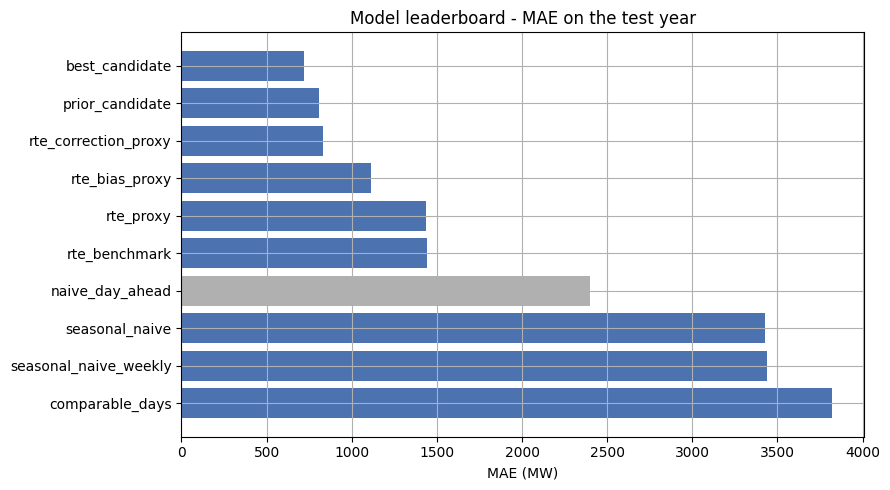

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
order = leaderboard.index[::-1]
colors = [GREY if m == BASELINE else "#4c72b0" for m in order]
ax.barh(order, leaderboard.loc[order, "MAE_MW"], color=colors)
ax.set_xlabel("MAE (MW)")
ax.set_title("Model leaderboard - MAE on the test year")
plt.tight_layout()
plt.show()

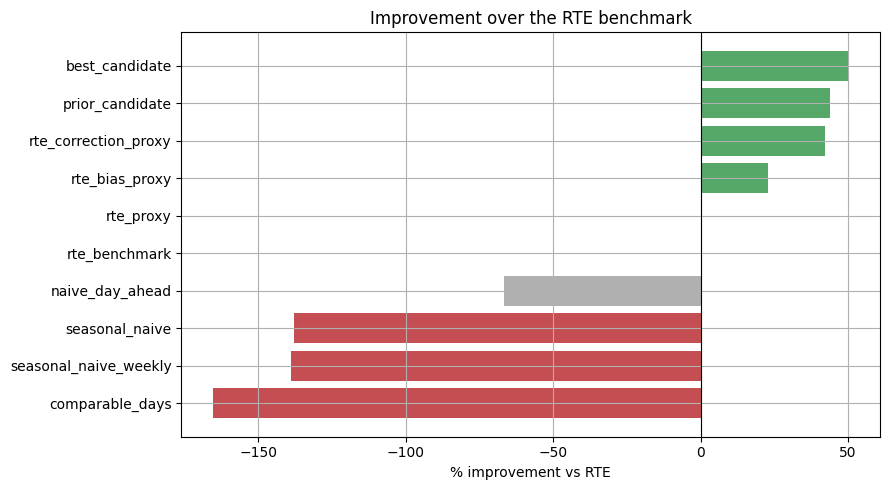

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
order = leaderboard["vs_rte_pct"].sort_values().index
colors = [
    GREY if m == BASELINE else ("#c44e52" if v < 0 else "#55a868")
    for m, v in zip(order, leaderboard.loc[order, "vs_rte_pct"])
]
ax.barh(order, leaderboard.loc[order, "vs_rte_pct"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("% improvement vs RTE")
ax.set_title("Improvement over the RTE benchmark")
plt.tight_layout()
plt.show()

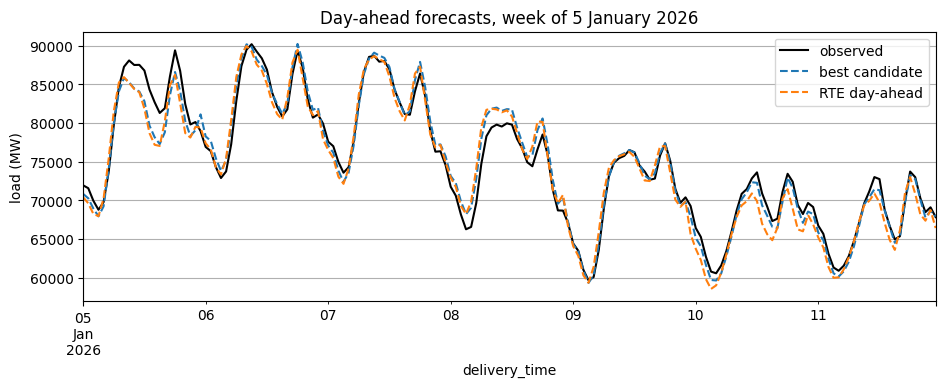

In [10]:
week = slice("2026-01-05", "2026-01-11")
fig, ax = plt.subplots()
actual_utc.loc[week].plot(ax=ax, label="observed", color="black", linewidth=1.5)
matched.loc[week, "selected_prediction_mw"].plot(ax=ax, label="best candidate", linestyle="--")
matched.loc[week, "rte_prediction_mw"].plot(ax=ax, label="RTE day-ahead", linestyle="--")
ax.set_ylabel("load (MW)")
ax.set_title("Day-ahead forecasts, week of 5 January 2026")
ax.legend()
plt.show()

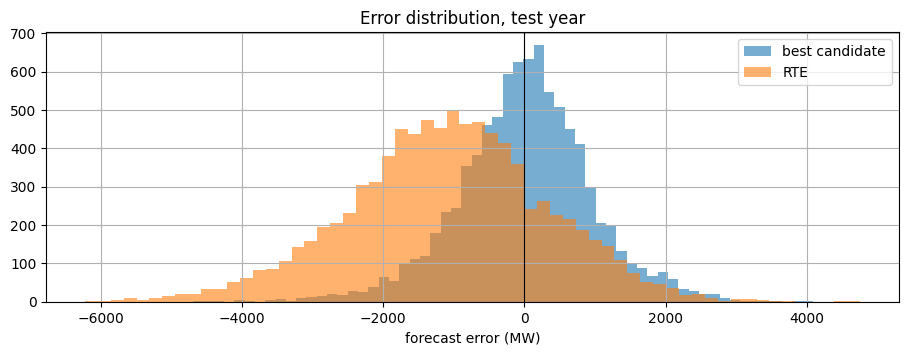

In [11]:
errors = pd.DataFrame({
    "best candidate": matched["selected_prediction_mw"] - actual_utc.reindex(matched.index),
    "RTE": matched["rte_prediction_mw"] - actual_utc.reindex(matched.index),
}).dropna()

fig, ax = plt.subplots()
ax.hist(errors["best candidate"], bins=60, alpha=0.6, label="best candidate")
ax.hist(errors["RTE"], bins=60, alpha=0.6, label="RTE")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("forecast error (MW)")
ax.set_title("Error distribution, test year")
ax.legend()
plt.show()

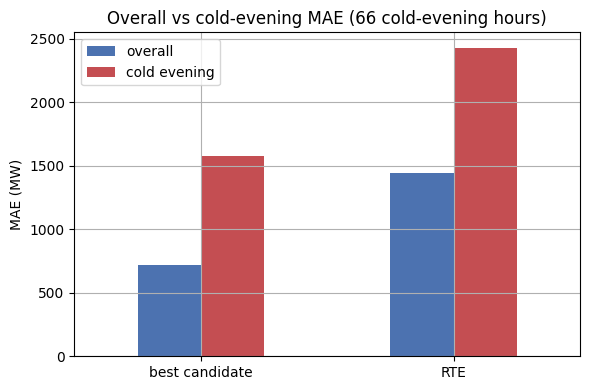

In [12]:
cold_mask = matched["cold_evening"].astype(bool)
segment_mae = pd.DataFrame({
    "overall": [
        score(actual_utc, matched["selected_prediction_mw"])["MAE_MW"],
        score(actual_utc, matched["rte_prediction_mw"])["MAE_MW"],
    ],
    "cold evening": [
        score(actual_utc, matched.loc[cold_mask, "selected_prediction_mw"])["MAE_MW"],
        score(actual_utc, matched.loc[cold_mask, "rte_prediction_mw"])["MAE_MW"],
    ],
}, index=["best candidate", "RTE"])

fig, ax = plt.subplots(figsize=(6, 4))
segment_mae.plot.bar(ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_ylabel("MAE (MW)")
ax.set_title(f"Overall vs cold-evening MAE ({int(cold_mask.sum())} cold-evening hours)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()